![JohnSnowLabs](https://nlp.johnsnowlabs.com/assets/images/logo.png)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JohnSnowLabs/visual-nlp-workshop/blob/master/jupyter/Dicom/SparkOcrDicomFlaggingPretrainedPipelines.ipynb)

# Dicom de-identification with text flagging pretrained pipelines

Many Dicom frames have no burned-in text at all. Running text detection, OCR and NER on them costs time and can only add false positives. This notebook shows three pretrained pipelines that do the full Dicom de-identification (metadata, OCR, NER and redaction of the pixels) and differ only in how they find the text regions:

| Pipeline | Text detection |
|---|---|
| `dicom_deid_generic_augmented_fast` | `ImageTextDetectorFast` (ONNX) on every frame |
| `dicom_deid_generic_augmented_flagging` | `ImageTextDetectorLite` (ONNX) flags the frames with text, `ImageTextDetectorFast` (ONNX) only runs on those |
| `dicom_deid_generic_augmented_flagging_ov` | `ImageTextDetectorLite` (OpenVINO, bf16) flags the frames with text, `ImageTextDetectorFast` (ONNX) only runs on those |


The rest of the pipeline is the same in the three: `DicomToImageV3` converts the frames to images, `ImageToTextV3` reads the text regions, the `ner_deid_sd` NER model and the Dicom metadata find the PHI, `PositionFinder` maps it to pixel coordinates, `DicomDrawRegions` covers it and `DicomMetadataDeidentifier` cleans the metadata tags.

The flagging pipelines need Visual NLP 7.0.1 or later.

## Install spark-ocr python package
Need specify:
- license
- path to `spark-ocr-assembly-[version].jar`
- or `secret` for Spark OCR
- `aws_access_key` and `aws_secret_key`for download pretrained models

For more details about Dicom de-identification please read:

 - [DICOM de-identification at scale in Visual NLP — Part 1.](https://medium.com/john-snow-labs/dicom-de-identification-at-scale-in-visual-nlp-part-1-68784177f5f0)

 - [DICOM de-identification at scale in Visual NLP — Part 2.](https://medium.com/john-snow-labs/dicom-de-identification-at-scale-in-visual-nlp-part-2-361af5e36412)

 - [DICOM de-identification at scale in Visual NLP — Part 3.](https://medium.com/john-snow-labs/dicom-de-identification-at-scale-in-visual-nlp-part-3-61cecc3adb56)

In [1]:
license = ""
secret = ""
nlp_secret = ""
aws_access_key = ""
aws_secret_key = ""

version = secret.split("-")[0]
spark_ocr_jar_path = "../../../target/scala-2.12"

## Initialization of spark session

In [2]:
from sparkocr import start
import os

if license:
    os.environ['JSL_OCR_LICENSE'] = license
    os.environ['SPARK_NLP_LICENSE'] = license

if aws_access_key:
    os.environ['AWS_ACCESS_KEY'] = aws_access_key
    os.environ['AWS_SECRET_ACCESS_KEY'] = aws_secret_key

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

spark = start(secret=secret,
              nlp_secret=nlp_secret,
              jar_path=spark_ocr_jar_path,
              nlp_internal="7.0.0")

spark

## Import Spark OCR transformers

In [3]:
import pandas as pd
import pydicom

import sparkocr
from sparkocr.transformers import *
from sparkocr.pretrained import PretrainedPipeline
from sparkocr.utils import *
from sparkocr.enums import *

from pyspark.ml import PipelineModel
import pyspark.sql.functions as F

print(f"Spark OCR version: {sparkocr.version()}")

Spark OCR version: 7.0.1rc2


## Read dicom objects as binary file
We use two sample files with burned-in PHI, `John_Stiles.dcm` and `Martin_Chad.dcm`. To also have a frame without text, we crop the center of `Martin_Chad.dcm`, where there is only the x-ray, and save it as a new Dicom file.

In [4]:
data_path = "./../data/dicom/"
no_text_path = "./../data/dicom/no_text/"
os.makedirs(no_text_path, exist_ok=True)

# center of the x-ray, without burned-in text
ds = pydicom.dcmread(data_path + "Martin_Chad.dcm")
crop = ds.pixel_array[511:1511, 511:1511].copy()
ds.Rows, ds.Columns = crop.shape
ds.PixelData = crop.tobytes()
ds.save_as(no_text_path + "Martin_Chad_no_text.dcm")

dicom_paths = [data_path + "John_Stiles.dcm", data_path + "Martin_Chad.dcm", no_text_path + "Martin_Chad_no_text.dcm"]
dicom_df = spark.read.format("binaryFile").load(dicom_paths)

dicom_df.select("path", "modificationTime", "length").show(10, False)

+----------------------------------------------------------------------------------------+-----------------------+-------+
|path                                                                                    |modificationTime       |length |
+----------------------------------------------------------------------------------------+-----------------------+-------+
|file:/home/ubuntu/dicom_flag/workshop/jupyter/data/dicom/Martin_Chad.dcm                |2026-11-09 10:36:18.846|8178988|
|file:/home/ubuntu/dicom_flag/workshop/jupyter/data/dicom/no_text/Martin_Chad_no_text.dcm|2026-11-09 11:07:40.475|2002020|
|file:/home/ubuntu/dicom_flag/workshop/jupyter/data/dicom/John_Stiles.dcm                |2026-11-09 10:36:18.38 |640574 |
+----------------------------------------------------------------------------------------+-----------------------+-------+



## Show original Dicom

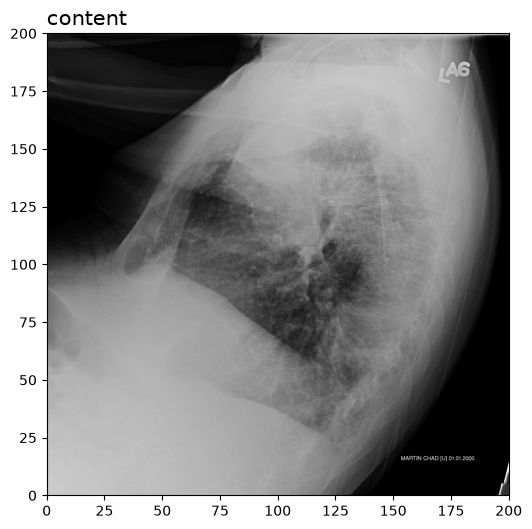

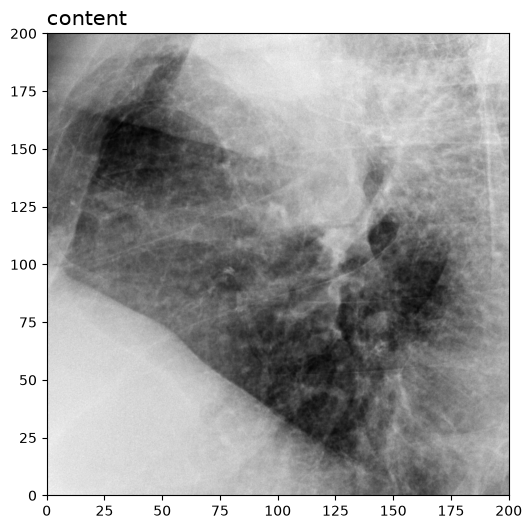

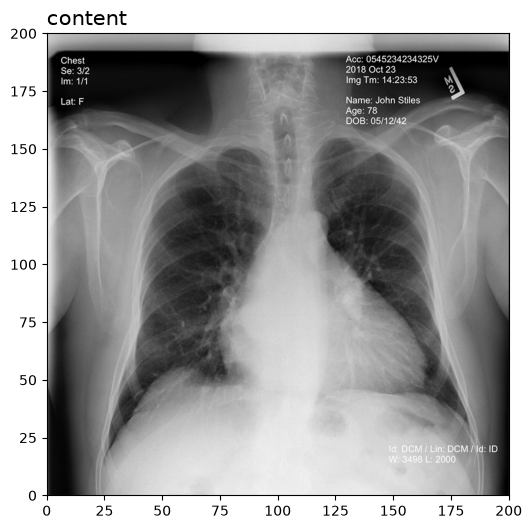

In [5]:
display_dicom(df=dicom_df, fields="content", limit_frame=1, show_meta=False, limit=3, width=300)

## Helper to show the detection results
A pretrained pipeline is a `PipelineModel`. Running its stages up to `PositionFinder` (all but `DicomDrawRegions` and `DicomMetadataDeidentifier`) keeps the intermediate columns, one row per frame:

1. **flag_regions** — the regions found by `ImageTextDetectorLite` (only in the flagging pipelines).
2. **text_regions** — the regions found by `ImageTextDetectorFast` and read by the OCR.
3. **phi_entities** — the PHI chunks found by the NER and the metadata (`deid_merged_chunk`).
4. **text** — the OCR text.

In [6]:
def detection_results(pipeline, df):
    intermediate = PipelineModel(stages=pipeline.model.stages[:-2]).transform(df).cache()
    columns = [F.element_at(F.split("path", "/"), -1).alias("file"), F.col("pagenum").alias("frame")]
    if "flag_regions" in intermediate.columns:
        columns.append(F.size("flag_regions").alias("flag_regions"))
    columns += [F.size("text_regions").alias("text_regions"),
                F.size("deid_merged_chunk").alias("phi_entities"),
                F.regexp_replace("text", "\n", " | ").alias("text")]
    return intermediate, intermediate.select(*columns).orderBy("file", "frame")


def show_phi(intermediate, name):
    intermediate.filter(F.col("path").contains(name)).withColumn("res", F.explode("deid_merged_chunk")) \
        .select(
            F.col("res.result").alias("Detected PHI"),
            F.col("res.metadata.entity").alias("Entity Type"),
            F.col("res.metadata.confidence").alias("Confidence")
        ).show(20, False)


summary = {}

## Pretrained Pipeline #1: `dicom_deid_generic_augmented_fast`
`ImageTextDetectorFast` (ONNX) finds the text regions on every frame, so the OCR and the NER run on every frame too.

In [7]:
pipeline = PretrainedPipeline("dicom_deid_generic_augmented_fast", "en", "clinical/ocr")
[type(stage).__name__ for stage in pipeline.model.stages]

dicom_deid_generic_augmented_fast download started this may take some time.


Approx size to download 1.6 GB
[ | ]

dicom_deid_generic_augmented_fast download started this may take some time.
Approximate size to download 1.6 GB


26/11/09 11:07:47 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/11/09 11:07:47 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


Download done! Loading the resource.


[ / ]

... (8 outputs left out)

[ — ]

[ \ ]

[OK!]

['DicomToMetadata',
 'DicomToImageV3',
 'ImageTextDetectorFast',
 'ImageToTextV3',
 'DicomDeidentifier',
 'PipelineModel',
 'PositionFinder',
 'DicomDrawRegions',
 'DicomMetadataDeidentifier']

### Detection results
One row per frame. Fast also runs on `Martin_Chad_no_text.dcm`.

In [8]:
intermediate, detections = detection_results(pipeline, dicom_df)
summary["dicom_deid_generic_augmented_fast"] = detections.drop("text").toPandas()
detections.show(10, 100)

/home/ubuntu/.venv/lib/python3.12/site-packages/pyspark/sql/dataframe.py:168: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


26/11/09 11:08:19 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


11:08:23, INFO Run DicomToMetadata
11:08:23, INFO Run DicomToMetadata
11:08:23, INFO Run DicomToMetadata


11:08:30, INFO DicomToMetadata : Total Rules Extracted 156
11:08:30, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:08:30, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER


11:08:31, INFO DicomToMetadata : Total Rules Extracted 156
11:08:31, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:08:31, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:08:31, INFO DicomToMetadata : Total Rules Extracted 156
11:08:31, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:08:31, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER


11:08:32, INFO Run DicomToImageV3


... (4 outputs left out)

2026-11-09 11:08:44.265165473 [W:onnxruntime:ort-java, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


11:08:46, INFO Run DicomDeidentifier
11:08:47, INFO Run DicomDeidentifier


26/11/09 11:08:47 WARN PositionFinder: Empty or null entity value is not allowed.
11:08:47, INFO Run DicomDeidentifier


+-----------------------+-----+------------+------------+----------------------------------------------------------------------------------------------------+
|                   file|frame|text_regions|phi_entities|                                                                                                text|
+-----------------------+-----+------------+------------+----------------------------------------------------------------------------------------------------+
|        John_Stiles.dcm|    0|          13|           4|Wi 3498 1: 2000 |   DOB: 05/12/42 |  Age: 78 |  Name: John Stiles |  Lat: F |  Im: 1/1 |  Img Tm:...|
|        Martin_Chad.dcm|    0|           2|           1|                                                                      MARTIN CHAD [U] 01.01.2000 |  |
|Martin_Chad_no_text.dcm|    0|           0|           0|                                                                                                    |
+-----------------------+-----+------------+--

### Detected PHI in `John_Stiles.dcm`

In [9]:
show_phi(intermediate, "John_Stiles")

+-------------------+-----------+----------+
|Detected PHI       |Entity Type|Confidence|
+-------------------+-----------+----------+
|05/12/42           |DATE       |0.9731    |
|John Stiles        |NAME       |0.98915   |
|2018 Oct 23        |DATE       |0.7801333 |
|Acc: 0545234234325V|UNK        |NULL      |
+-------------------+-----------+----------+



26/11/09 11:08:48 WARN DAGScheduler: Broadcasting large task binary with size 1009.7 KiB
26/11/09 11:08:48 WARN DAGScheduler: Broadcasting large task binary with size 1009.7 KiB


### Display the de-identified Dicom

/home/ubuntu/.venv/lib/python3.12/site-packages/pyspark/sql/dataframe.py:168: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


11:08:50, INFO Run DicomToMetadata
11:08:50, INFO DicomToMetadata : Total Rules Extracted 156
11:08:50, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:08:50, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:08:50, INFO Run DicomToMetadata
11:08:50, INFO Run DicomToImageV3
11:08:50, INFO DicomToMetadata : Total Rules Extracted 156
11:08:50, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:08:50, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:08:50, INFO DicomToImageV3: Lazy read, number of frames: 1
11:08:50, INFO Run DicomToMetadata
11:08:50, INFO DicomToMetadata : Total Rules Extracted 156
11:08:50, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:08:50, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:08:50, INFO DicomToImageV3: Image Width: 1600, Image Height: 1600
11:08:50, INFO DicomToImageV3: Compression Triggered Image Quality: 80
11:08:50

11:08:50, INFO DicomToImageV3: Image Width: 4044, Image Height: 4044
11:08:50, INFO DicomToImageV3: Compression Triggered Image Quality: 80


11:08:50, INFO Run DicomDeidentifier
26/11/09 11:08:50 WARN PositionFinder: Empty or null entity value is not allowed.
11:08:50, INFO Run DicomDeidentifier


11:08:50, INFO Run DicomDeidentifier


11:08:51, INFO DicomDrawRegions: file:/home/ubuntu/dicom_flag/workshop/jupyter/data/dicom/John_Stiles.dcm
11:08:51, INFO DicomDrawRegions: Original Size: 640574
11:08:51, INFO DicomDrawRegions: Photometric Interpretation: MONOCHROME2
11:08:51, INFO DicomDrawRegions: Transfer Syntax: 1.2.840.10008.1.2.1
11:08:51, INFO DicomDrawRegions: Pixel Representation: 0
11:08:51, INFO DicomDrawRegions: Bits Allocated: 8
11:08:51, INFO DicomDrawRegions: Bits Stored: 8
11:08:51, INFO DicomDrawRegions: High Bit: 7
11:08:51, INFO DicomDrawRegions: Internal Configuration Non-Compression
11:08:51, INFO DicomDrawRegions: Using Transfer Syntax 1.2.840.10008.1.2.1
11:08:51, INFO DicomDrawRegions: Pixel Shape (800, 800)
11:08:51, INFO DicomDrawRegions: Shape: (800, 800)
11:08:51, INFO DicomDrawRegions: Process 0 frame
11:08:51, INFO DicomDrawRegions: Compress PixelData With: 1.2.840.10008.1.2.1
11:08:51, INFO DicomDrawRegions: Updated size: 640617
11:08:51, INFO DicomDrawRegions: file:/home/ubuntu/dicom_fla

11:08:59, INFO DicomMetadataDeidentifier : Tags to Ignore : set()
11:08:59, ERROR DicomMetadataDeidentifier : Tag '0008002A' Present in Strategy file but missing in Dicom.
11:08:59, ERROR DicomMetadataDeidentifier : Tag '0008009C' Present in Strategy file but missing in Dicom.
11:08:59, ERROR DicomMetadataDeidentifier : Tag '0008010D' Present in Strategy file but missing in Dicom.
11:08:59, ERROR DicomMetadataDeidentifier : Tag '001021D0' Present in Strategy file but missing in Dicom.
11:08:59, ERROR DicomMetadataDeidentifier : Tag '001021F0' Present in Strategy file but missing in Dicom.
11:08:59, ERROR DicomMetadataDeidentifier : Tag '0018700C' Present in Strategy file but missing in Dicom.
11:08:59, INFO DicomMetadataDeidentifier : Updating Tag '0020000D' VR 'UI'
11:08:59, ERROR DicomMetadataDeidentifier : Tag '0020000E' Present in Strategy file but missing in Dicom.
11:08:59, ERROR DicomMetadataDeidentifier : Tag '0038001E' Present in Strategy file but missing in Dicom.
11:08:59, E

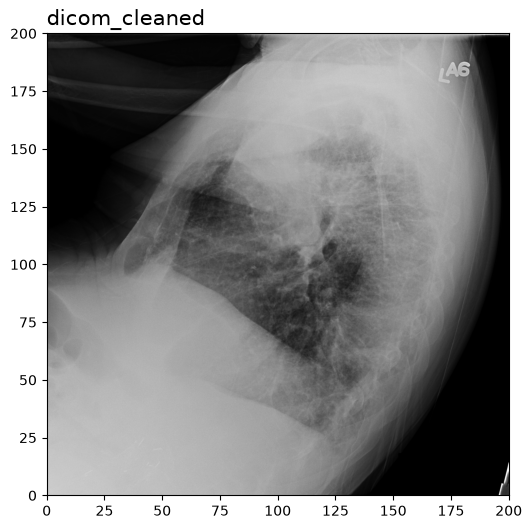

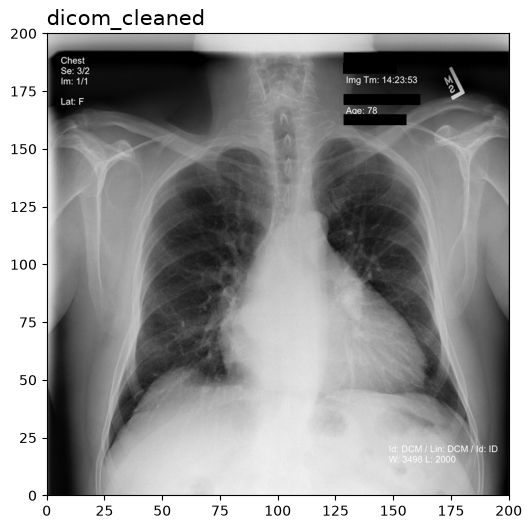

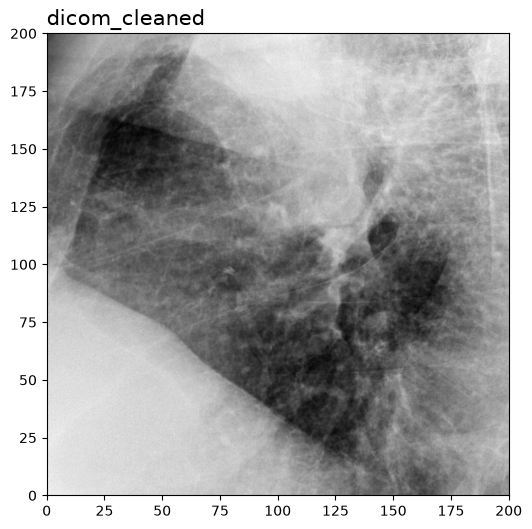

In [10]:
result = pipeline.transform(dicom_df).cache()
display_dicom(df=result, fields="dicom_cleaned", limit_frame=1, show_meta=False, limit=3, width=300)

## Pretrained Pipeline #2: `dicom_deid_generic_augmented_flagging`
`ImageTextDetectorLite` (ONNX), text flagging model, runs first on every frame and writes `flag_regions`. `ImageTextDetectorFast` (ONNX) reads them through `flagRegionsCol`: the frames where Lite found no text are skipped and get no regions, so Fast, the OCR and the NER only run on the frames with text.

In [11]:
pipeline = PretrainedPipeline("dicom_deid_generic_augmented_flagging", "en", "clinical/ocr")
[type(stage).__name__ for stage in pipeline.model.stages]

dicom_deid_generic_augmented_flagging download started this may take some time.
Approx size to download 1.6 GB
[ | ]

26/11/09 11:09:00 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/11/09 11:09:00 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/11/09 11:09:00 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


dicom_deid_generic_augmented_flagging download started this may take some time.
Approximate size to download 1.6 GB


Download done! Loading the resource.


[ / ]

[ — ]

[ \ ]

[ | ]

[OK!]

['DicomToMetadata',
 'DicomToImageV3',
 'ImageTextDetectorLite',
 'ImageTextDetectorFast',
 'ImageToTextV3',
 'DicomDeidentifier',
 'PipelineModel',
 'PositionFinder',
 'DicomDrawRegions',
 'DicomMetadataDeidentifier']

In [12]:
fast = [stage for stage in pipeline.model.stages if isinstance(stage, ImageTextDetectorFast)][0]
print("flagRegionsCol:", fast.getOrDefault("flagRegionsCol"))

flagRegionsCol: flag_regions


### Detection results
One row per frame. `Martin_Chad_no_text.dcm` has no `flag_regions`, so Fast skips it and it gets no `text_regions`.

In [13]:
intermediate, detections = detection_results(pipeline, dicom_df)
summary["dicom_deid_generic_augmented_flagging"] = detections.drop("text").toPandas()
detections.show(10, 100)

11:09:14, INFO Run DicomToMetadata
11:09:14, INFO Run DicomToMetadata
11:09:14, INFO DicomToMetadata : Total Rules Extracted 156
11:09:14, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:14, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:14, INFO DicomToMetadata : Total Rules Extracted 156
11:09:14, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:14, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:14, INFO Run DicomToImageV3
11:09:14, INFO DicomToImageV3: Lazy read, number of frames: 1
11:09:14, INFO Run DicomToMetadata
11:09:14, INFO Run DicomToImageV3
11:09:14, INFO DicomToImageV3: Image Width: 1600, Image Height: 1600
11:09:14, INFO DicomToImageV3: Compression Triggered Image Quality: 80
11:09:14, INFO DicomToImageV3: Lazy read, number of frames: 1


11:09:14, INFO DicomToImageV3: Image Width: 2000, Image Height: 2000
11:09:14, INFO DicomToImageV3: Compression Triggered Image Quality: 80


11:09:14, INFO Run DicomDeidentifier
26/11/09 11:09:14 WARN PositionFinder: Empty or null entity value is not allowed.
11:09:14, INFO Run DicomDeidentifier


11:09:21, INFO DicomToMetadata : Total Rules Extracted 156
11:09:21, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:21, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:21, INFO Run DicomToImageV3


11:09:29, INFO DicomToImageV3: Lazy read, number of frames: 1


11:09:30, INFO DicomToImageV3: Image Width: 4044, Image Height: 4044
11:09:30, INFO DicomToImageV3: Compression Triggered Image Quality: 80


11:09:31, INFO Run DicomDeidentifier
26/11/09 11:09:31 WARN DAGScheduler: Broadcasting large task binary with size 1001.8 KiB
26/11/09 11:09:31 WARN DAGScheduler: Broadcasting large task binary with size 1003.0 KiB
26/11/09 11:09:31 WARN DAGScheduler: Broadcasting large task binary with size 1006.7 KiB


+-----------------------+-----+------------+------------+------------+----------------------------------------------------------------------------------------------------+
|                   file|frame|flag_regions|text_regions|phi_entities|                                                                                                text|
+-----------------------+-----+------------+------------+------------+----------------------------------------------------------------------------------------------------+
|        John_Stiles.dcm|    0|          12|          13|           4|Wi 3498 1: 2000 |   DOB: 05/12/42 |  Age: 78 |  Name: John Stiles |  Lat: F |  Im: 1/1 |  Img Tm:...|
|        Martin_Chad.dcm|    0|           2|           2|           1|                                                                      MARTIN CHAD [U] 01.01.2000 |  |
|Martin_Chad_no_text.dcm|    0|           0|           0|           0|                                                                      

26/11/09 11:09:31 WARN DAGScheduler: Broadcasting large task binary with size 1003.5 KiB


### Detected PHI in `John_Stiles.dcm`

In [14]:
show_phi(intermediate, "John_Stiles")

26/11/09 11:09:31 WARN DAGScheduler: Broadcasting large task binary with size 1025.5 KiB
26/11/09 11:09:31 WARN DAGScheduler: Broadcasting large task binary with size 1025.5 KiB


+-------------------+-----------+----------+
|Detected PHI       |Entity Type|Confidence|
+-------------------+-----------+----------+
|05/12/42           |DATE       |0.9731    |
|John Stiles        |NAME       |0.98915   |
|2018 Oct 23        |DATE       |0.7801333 |
|Acc: 0545234234325V|UNK        |NULL      |
+-------------------+-----------+----------+



### Display the de-identified Dicom

/home/ubuntu/.venv/lib/python3.12/site-packages/pyspark/sql/dataframe.py:168: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


26/11/09 11:09:32 WARN SparkContext: The path /home/ubuntu/dicom_flag/sparkocr_flag2/sparkocr/resources/ocr/dicom/first_names.all.txt has been added already. Overwriting of added paths is not supported in the current version.
26/11/09 11:09:32 WARN SparkContext: The path /home/ubuntu/dicom_flag/sparkocr_flag2/sparkocr/resources/ocr/dicom/last_names.all.txt has been added already. Overwriting of added paths is not supported in the current version.


11:09:32, INFO Run DicomToMetadata
11:09:32, INFO DicomToMetadata : Total Rules Extracted 156
11:09:32, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:32, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:32, INFO Run DicomToImageV3
11:09:32, INFO DicomToImageV3: Lazy read, number of frames: 1
11:09:32, INFO Run DicomToMetadata
11:09:32, INFO DicomToMetadata : Total Rules Extracted 156
11:09:32, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:32, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:32, INFO DicomToImageV3: Image Width: 1600, Image Height: 1600
11:09:32, INFO DicomToImageV3: Compression Triggered Image Quality: 80
11:09:32, INFO Run DicomToMetadata
11:09:32, INFO Run DicomToImageV3
11:09:32, INFO DicomToImageV3: Lazy read, number of frames: 1
11:09:32, INFO DicomToMetadata : Total Rules Extracted 156
11:09:32, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09

11:09:33, INFO Run DicomDeidentifier
26/11/09 11:09:33 WARN PositionFinder: Empty or null entity value is not allowed.


11:09:33, INFO DicomToImageV3: Image Width: 4044, Image Height: 4044
11:09:33, INFO DicomToImageV3: Compression Triggered Image Quality: 80
11:09:33, INFO Run DicomDeidentifier


11:09:34, INFO Run DicomDeidentifier


11:09:34, INFO DicomDrawRegions: file:/home/ubuntu/dicom_flag/workshop/jupyter/data/dicom/Martin_Chad.dcm
11:09:34, INFO DicomDrawRegions: file:/home/ubuntu/dicom_flag/workshop/jupyter/data/dicom/John_Stiles.dcm
11:09:34, INFO DicomDrawRegions: Original Size: 640574
11:09:34, INFO DicomDrawRegions: Photometric Interpretation: MONOCHROME2
11:09:34, INFO DicomDrawRegions: Transfer Syntax: 1.2.840.10008.1.2.1
11:09:34, INFO DicomDrawRegions: Pixel Representation: 0
11:09:34, INFO DicomDrawRegions: Bits Allocated: 8
11:09:34, INFO DicomDrawRegions: Bits Stored: 8
11:09:34, INFO DicomDrawRegions: High Bit: 7
11:09:34, INFO DicomDrawRegions: Internal Configuration Non-Compression
11:09:34, INFO DicomDrawRegions: Using Transfer Syntax 1.2.840.10008.1.2.1
11:09:34, INFO DicomDrawRegions: Pixel Shape (800, 800)
11:09:34, INFO DicomDrawRegions: Shape: (800, 800)
11:09:34, INFO DicomDrawRegions: Process 0 frame
11:09:34, INFO DicomDrawRegions: Compress PixelData With: 1.2.840.10008.1.2.1
11:09:34

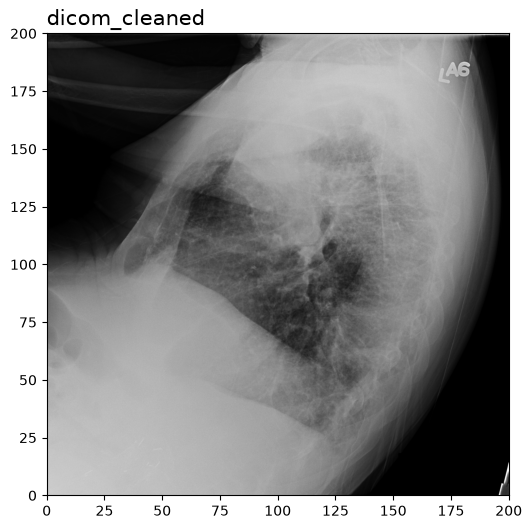

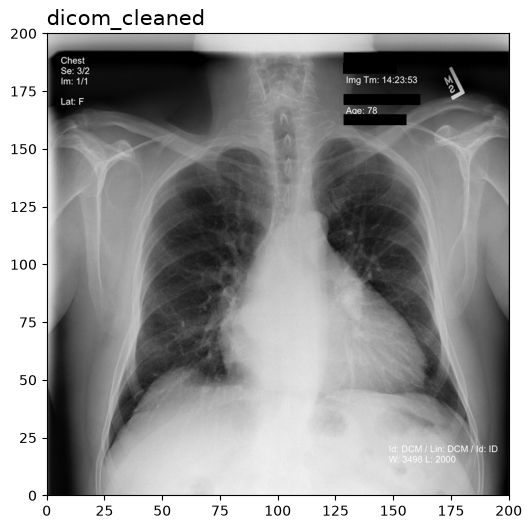

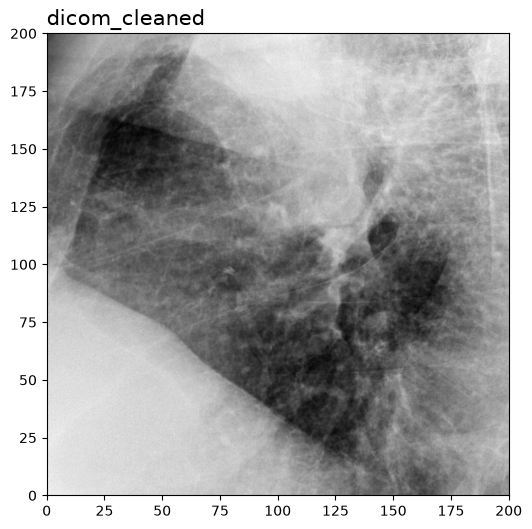

In [15]:
result = pipeline.transform(dicom_df).cache()
display_dicom(df=result, fields="dicom_cleaned", limit_frame=1, show_meta=False, limit=3, width=300)

## Pretrained Pipeline #3: `dicom_deid_generic_augmented_flagging_ov`
The same as #2, with `ImageTextDetectorLite` in OpenVINO (bf16) instead of ONNX. On Intel CPUs it is the faster of the two flagging pipelines.

In [16]:
pipeline = PretrainedPipeline("dicom_deid_generic_augmented_flagging_ov", "en", "clinical/ocr")
[type(stage).__name__ for stage in pipeline.model.stages]

dicom_deid_generic_augmented_flagging_ov download started this may take some time.
Approx size to download 1.6 GB
[ | ]

26/11/09 11:09:35 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/11/09 11:09:35 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/11/09 11:09:35 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


dicom_deid_generic_augmented_flagging_ov download started this may take some time.
Approximate size to download 1.6 GB


Download done! Loading the resource.


[ / ]

[ — ]

[ \ ]

[ | ]

[OK!]

['DicomToMetadata',
 'DicomToImageV3',
 'ImageTextDetectorLite',
 'ImageTextDetectorFast',
 'ImageToTextV3',
 'DicomDeidentifier',
 'PipelineModel',
 'PositionFinder',
 'DicomDrawRegions',
 'DicomMetadataDeidentifier']

In [17]:
fast = [stage for stage in pipeline.model.stages if isinstance(stage, ImageTextDetectorFast)][0]
print("flagRegionsCol:", fast.getOrDefault("flagRegionsCol"))

flagRegionsCol: flag_regions


### Detection results
One row per frame. `Martin_Chad_no_text.dcm` has no `flag_regions`, so Fast skips it and it gets no `text_regions`.

In [18]:
intermediate, detections = detection_results(pipeline, dicom_df)
summary["dicom_deid_generic_augmented_flagging_ov"] = detections.drop("text").toPandas()
detections.show(10, 100)

11:09:49, INFO Run DicomToMetadata
11:09:49, INFO Run DicomToMetadata
11:09:49, INFO DicomToMetadata : Total Rules Extracted 156
11:09:49, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:49, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:49, INFO DicomToMetadata : Total Rules Extracted 156
11:09:49, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:49, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:49, INFO Run DicomToImageV3
11:09:49, INFO DicomToImageV3: Lazy read, number of frames: 1
11:09:49, INFO DicomToImageV3: Image Width: 1600, Image Height: 1600
11:09:49, INFO DicomToImageV3: Compression Triggered Image Quality: 80
11:09:49, INFO Run DicomToMetadata
11:09:49, INFO DicomToMetadata : Total Rules Extracted 156
11:09:49, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:49, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:49

11:09:49, INFO DicomToImageV3: Image Width: 2000, Image Height: 2000
11:09:49, INFO DicomToImageV3: Compression Triggered Image Quality: 80


11:09:50, INFO DicomToImageV3: Image Width: 4044, Image Height: 4044
11:09:50, INFO DicomToImageV3: Compression Triggered Image Quality: 80


11:09:50, INFO Run DicomDeidentifier
26/11/09 11:09:50 WARN PositionFinder: Empty or null entity value is not allowed.


11:09:50, INFO Run DicomDeidentifier
11:09:51, INFO Run DicomDeidentifier


26/11/09 11:09:51 WARN DAGScheduler: Broadcasting large task binary with size 1001.8 KiB


26/11/09 11:09:51 WARN DAGScheduler: Broadcasting large task binary with size 1003.0 KiB
26/11/09 11:09:51 WARN DAGScheduler: Broadcasting large task binary with size 1006.7 KiB


+-----------------------+-----+------------+------------+------------+----------------------------------------------------------------------------------------------------+
|                   file|frame|flag_regions|text_regions|phi_entities|                                                                                                text|
+-----------------------+-----+------------+------------+------------+----------------------------------------------------------------------------------------------------+
|        John_Stiles.dcm|    0|          12|          13|           4|Wi 3498 1: 2000 |   DOB: 05/12/42 |  Age: 78 |  Name: John Stiles |  Lat: F |  Im: 1/1 |  Img Tm:...|
|        Martin_Chad.dcm|    0|           2|           2|           1|                                                                      MARTIN CHAD [U] 01.01.2000 |  |
|Martin_Chad_no_text.dcm|    0|           0|           0|           0|                                                                      

26/11/09 11:09:51 WARN DAGScheduler: Broadcasting large task binary with size 1003.6 KiB


### Detected PHI in `John_Stiles.dcm`

In [19]:
show_phi(intermediate, "John_Stiles")

26/11/09 11:09:51 WARN DAGScheduler: Broadcasting large task binary with size 1025.5 KiB
26/11/09 11:09:51 WARN DAGScheduler: Broadcasting large task binary with size 1025.5 KiB


+-------------------+-----------+----------+
|Detected PHI       |Entity Type|Confidence|
+-------------------+-----------+----------+
|05/12/42           |DATE       |0.9731    |
|John Stiles        |NAME       |0.98915   |
|2018 Oct 23        |DATE       |0.7801333 |
|Acc: 0545234234325V|UNK        |NULL      |
+-------------------+-----------+----------+



### Display the de-identified Dicom

/home/ubuntu/.venv/lib/python3.12/site-packages/pyspark/sql/dataframe.py:168: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


26/11/09 11:09:52 WARN SparkContext: The path /home/ubuntu/dicom_flag/sparkocr_flag2/sparkocr/resources/ocr/dicom/first_names.all.txt has been added already. Overwriting of added paths is not supported in the current version.
26/11/09 11:09:52 WARN SparkContext: The path /home/ubuntu/dicom_flag/sparkocr_flag2/sparkocr/resources/ocr/dicom/last_names.all.txt has been added already. Overwriting of added paths is not supported in the current version.


11:09:53, INFO Run DicomToMetadata
11:09:53, INFO Run DicomToMetadata
11:09:53, INFO DicomToMetadata : Total Rules Extracted 156
11:09:53, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:53, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:53, INFO DicomToMetadata : Total Rules Extracted 156
11:09:53, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:53, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:53, INFO Run DicomToImageV3
11:09:53, INFO DicomToImageV3: Lazy read, number of frames: 1
11:09:53, INFO Run DicomToMetadata
11:09:53, INFO Run DicomToImageV3
11:09:53, INFO DicomToImageV3: Lazy read, number of frames: 1
11:09:53, INFO DicomToMetadata : Total Rules Extracted 156
11:09:53, INFO DicomToMetadata : Total cleanTag Action Found : 0
11:09:53, INFO DicomToMetadata : Returning Metadata, Document Object and Tag Mapping for NER
11:09:53, INFO DicomToImageV3: Image Width: 1600, Im

11:09:53, INFO DicomToImageV3: Image Width: 4044, Image Height: 4044
11:09:53, INFO DicomToImageV3: Compression Triggered Image Quality: 80
11:09:53, INFO Run DicomDeidentifier
26/11/09 11:09:53 WARN PositionFinder: Empty or null entity value is not allowed.


11:09:53, INFO Run DicomDeidentifier


11:09:54, INFO Run DicomDeidentifier


11:09:54, INFO DicomDrawRegions: file:/home/ubuntu/dicom_flag/workshop/jupyter/data/dicom/John_Stiles.dcm
11:09:54, INFO DicomDrawRegions: Original Size: 640574
11:09:54, INFO DicomDrawRegions: Photometric Interpretation: MONOCHROME2
11:09:54, INFO DicomDrawRegions: Transfer Syntax: 1.2.840.10008.1.2.1
11:09:54, INFO DicomDrawRegions: Pixel Representation: 0
11:09:54, INFO DicomDrawRegions: Bits Allocated: 8
11:09:54, INFO DicomDrawRegions: Bits Stored: 8
11:09:54, INFO DicomDrawRegions: High Bit: 7
11:09:54, INFO DicomDrawRegions: Internal Configuration Non-Compression
11:09:54, INFO DicomDrawRegions: Using Transfer Syntax 1.2.840.10008.1.2.1
11:09:54, INFO DicomDrawRegions: Pixel Shape (800, 800)
11:09:54, INFO DicomDrawRegions: Shape: (800, 800)
11:09:54, INFO DicomDrawRegions: Process 0 frame
11:09:54, INFO DicomDrawRegions: Compress PixelData With: 1.2.840.10008.1.2.1
11:09:54, INFO DicomDrawRegions: Updated size: 640617
11:09:54, INFO DicomDrawRegions: file:/home/ubuntu/dicom_fla

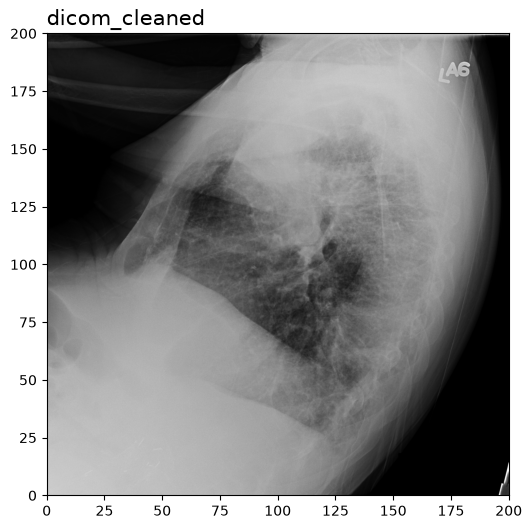

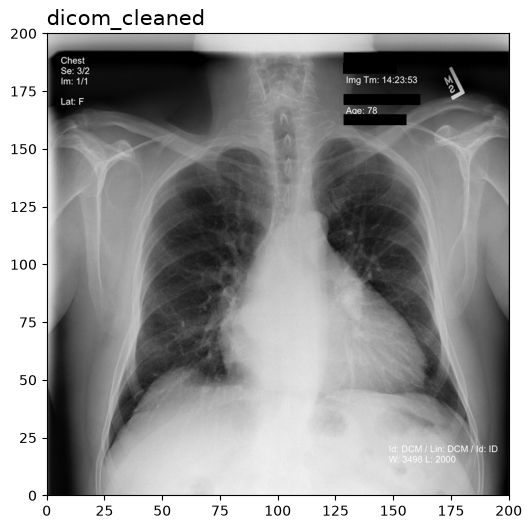

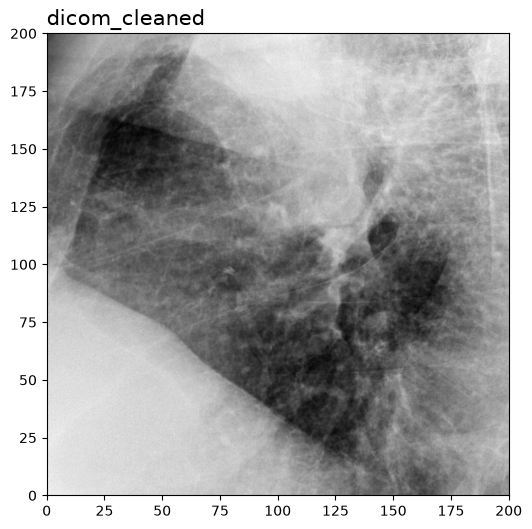

In [20]:
result = pipeline.transform(dicom_df).cache()
display_dicom(df=result, fields="dicom_cleaned", limit_frame=1, show_meta=False, limit=3, width=300)

## Compare the three pipelines
Regions and PHI entities found per frame by each pipeline.

In [21]:
comparison = pd.concat(summary, names=["pipeline"]).reset_index(level=0).reset_index(drop=True)
# Fast alone has no flag_regions
comparison["flag_regions"] = comparison["flag_regions"].astype("Int64")
comparison[["pipeline", "file", "frame", "flag_regions", "text_regions", "phi_entities"]]

,pipeline,file,frame,flag_regions,text_regions,phi_entities
0,dicom_deid_generic_augmented_fast,John_Stiles.dcm,0,<NA>,13,4
1,dicom_deid_generic_augmented_fast,Martin_Chad.dcm,0,<NA>,2,1
2,dicom_deid_generic_augmented_fast,Martin_Chad_no_text.dcm,0,<NA>,0,0
3,dicom_deid_generic_augmented_flagging,John_Stiles.dcm,0,12,13,4
4,dicom_deid_generic_augmented_flagging,Martin_Chad.dcm,0,2,2,1
5,dicom_deid_generic_augmented_flagging,Martin_Chad_no_text.dcm,0,0,0,0
6,dicom_deid_generic_augmented_flagging_ov,John_Stiles.dcm,0,12,13,4
7,dicom_deid_generic_augmented_flagging_ov,Martin_Chad.dcm,0,2,2,1
8,dicom_deid_generic_augmented_flagging_ov,Martin_Chad_no_text.dcm,0,0,0,0


## Which pipeline to use
The three pipelines cover the same PHI on the frames with text. Lite adds a cost on every frame and saves Fast, the OCR and the NER on the frames without text, so flagging pays off when most of the frames have no text.

In our CPU benchmark with these pipelines, flagging with Lite OpenVINO + Fast ONNX was faster than Fast ONNX alone when more than about 64% of the files had no text for 600×800 images, and more than about 56% for 1200×1600 images. Below that, use `dicom_deid_generic_augmented_fast`.

## Save Dicom To Disk
The `dicom_cleaned` column of the last pipeline is written back as `.dcm` files, one per input, named with the `ocr_` prefix.

In [22]:
# NBVAL_SKIP
output_path = "./../data/dicom/deidentified/"
from pyspark.sql.functions import *
from pyspark.sql.types import StringType

def get_name(path, keep_subfolder_level=0):
    path = path.split("/")
    path[-1] = path[-1].split('.')[0]
    return "/".join(path[-keep_subfolder_level-1:])

result.withColumn("fileName", udf(get_name, StringType())(col("path"))) \
    .write \
    .format("binaryFormat") \
    .option("type", "dicom") \
    .option("field", "dicom_cleaned") \
    .option("prefix", "ocr_") \
    .option("nameField", "fileName") \
    .mode("overwrite") \
    .save(output_path)

26/11/09 11:09:56 WARN BasicWriteTaskStatsTracker: Expected 1 files, but only saw 0. This could be due to the output format not writing empty files, or files being not immediately visible in the filesystem.
26/11/09 11:09:56 WARN BasicWriteTaskStatsTracker: Expected 1 files, but only saw 0. This could be due to the output format not writing empty files, or files being not immediately visible in the filesystem.
26/11/09 11:09:56 WARN BasicWriteTaskStatsTracker: Expected 1 files, but only saw 0. This could be due to the output format not writing empty files, or files being not immediately visible in the filesystem.
26/11/09 11:09:56 WARN BasicWriteTaskStatsTracker: Expected 1 files, but only saw 0. This could be due to the output format not writing empty files, or files being not immediately visible in the filesystem.


## Clean up
Removes the de-identified files and the Dicom without text created above.

In [23]:
%%bash
rm -r -f ./../data/dicom/deidentified ./../data/dicom/no_text